# Decision Trees and Random Forest – Loan Risk Modeling

**🔑 TARGET & FEATURE CLARITY**

Loan_Status   →  Approved / Rejected / Pending (or similar)

# 🌳 Decision Trees, Random Forest & XGBoost
## Loan Status Prediction using HDFC Loan Dataset

### Objective
- Build tree-based classification models
- Predict loan approval status
- Compare Decision Tree, Random Forest, and XGBoost
- Understand feature importance for business decisions

## 📘 Tree-Based Models Overview

### Decision Tree
- Rule-based splits
- Easy to interpret
- Can overfit

### Random Forest
- Ensemble of decision trees
- Reduces variance
- More stable predictions

### XGBoost
- Gradient boosted decision trees
- Sequentially corrects residual errors
- High predictive accuracy and built-in regularization

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from xgboost import XGBClassifier

In [3]:
df = pd.read_csv("hdfc_loan_dataset_full_enriched - hdfc_loan_dataset_full_enriched.csv")
df.head()

,Loan_ID,Bank,Customer_Name,Gender,Married,Dependents,Education,Employment_Status,Applicant_Income,Coapplicant_Income,...,Loan_to_Annual_Income,Customer_Sentiment,Religion,State,City,PIN_Code,Aadhaar_Synthetic,Phone_Number,Email,Occupation
0,HDFC100001,HDFC Bank,Rohan Verma,Male,No,2,Graduate,Salaried,56976,0,...,11.747,Positive,Hindu,Delhi,Dwarka,857743,6.940000e+11,9068671773,rohan.verma@example.in,Farmer
1,HDFC100002,HDFC Bank,Rohan Verma,Male,No,0,Graduate,Unemployed,1856,0,...,40.381,Negative,Hindu,Punjab,Ludhiana,863836,6.330000e+11,9990772625,rohan.verma@example.in,Civil Engineer
2,HDFC100003,HDFC Bank,Aditya Nair,Female,Yes,0,Graduate,Salaried,64553,0,...,3.082,Positive,Hindu,Maharashtra,Nagpur,834796,1.660000e+11,9195085016,aditya.nair@example.in,Medical Representative
3,HDFC100004,HDFC Bank,Ananya Joshi,Male,No,0,Graduate,Salaried,88450,0,...,0.621,Negative,Hindu,Gujarat,Vadodara,438590,5.528183e+10,9179335548,ananya.joshi@example.in,Marketing Executive
4,HDFC100005,HDFC Bank,Harpreet Singh,Male,Yes,3,Graduate,Self-Employed,9539,0,...,1.736,Neutral,Sikh,West Bengal,Kolkata,495224,1.560000e+11,9795137116,harpreet.singh@example.in,Shopkeeper


## 📊 Dataset Overview

The dataset contains:
- Applicant demographics
- Financial indicators
- Credit behavior
- Geographic and institutional data
- Textual fields (excluded from modeling)

Target variable:
➡️ `Loan_Status`

In [4]:
drop_cols = [
    'Loan_ID', 'Customer_Name', 'Phone_Number', 'Email',
    'Aadhaar_Synthetic', 'Application_Text',
    'Customer_Feedback', 'Agent_Notes', 'Unnamed: 39', 'Bank'
]

df_model = df.drop(columns=[col for col in drop_cols if col in df.columns])

In [5]:
# Fill missing categorical values
df_model['Business_Type'] = df_model['Business_Type'].fillna('Unknown')
df_model['Co-signer_Relationship'] = df_model['Co-signer_Relationship'].fillna('None')

df_model.isnull().sum()

Gender                         0
Married                        0
Dependents                     0
Education                      0
Employment_Status              0
Applicant_Income               0
Coapplicant_Income             0
Loan_Amount                    0
Loan_Term_Months               0
Credit_History                 0
Property_Area                  0
Age                            0
Loan_Status                    0
CIBIL_Score                    0
Annual_Household_Income        0
Debt_to_Income_Ratio           0
Purpose_of_Loan                0
Existing_EMIs                  0
Number_of_Previous_Loans       0
Default_History_Count          0
Employment_Length_Years        0
Business_Type                  0
Asset_Value                    0
Guarantor                      0
Co-signer_Relationship         0
Monthly_Expense                0
Organization_Type              0
Region_Branch                  0
Mobile_Verified                0
Email_Verified                 0
Institutio

In [6]:
target = 'Loan_Status'

X = df_model.drop(columns=[target])
y = df_model[target]

In [7]:
# Define numeric and categorical feature lists before initializing ColumnTransformer
num_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_features = X.select_dtypes(include=['object', 'string']).columns.tolist()

num_features, cat_features

(['Dependents',
  'Applicant_Income',
  'Coapplicant_Income',
  'Loan_Amount',
  'Loan_Term_Months',
  'Credit_History',
  'Age',
  'CIBIL_Score',
  'Annual_Household_Income',
  'Debt_to_Income_Ratio',
  'Existing_EMIs',
  'Number_of_Previous_Loans',
  'Default_History_Count',
  'Employment_Length_Years',
  'Asset_Value',
  'Monthly_Expense',
  'Loan_to_Annual_Income',
  'PIN_Code'],
 ['Gender',
  'Married',
  'Education',
  'Employment_Status',
  'Property_Area',
  'Purpose_of_Loan',
  'Business_Type',
  'Guarantor',
  'Co-signer_Relationship',
  'Organization_Type',
  'Region_Branch',
  'Mobile_Verified',
  'Email_Verified',
  'Institutional_Relationships',
  'Customer_Sentiment',
  'Religion',
  'State',
  'City',
  'Occupation'])

In [8]:
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features)
    ],
    remainder='passthrough'
)

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# **🌳 DECISION TREE**

In [10]:
dt_pipeline = Pipeline([
    ('preprocess', preprocessor),
    ('model', DecisionTreeClassifier(max_depth=6, random_state=42))
])

dt_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['Approved','Rejected']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](37,)","['Gender','Married','Dependents',...,'City','PIN_Code','Occupation']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,37
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all 

In [11]:
dt_pred = dt_pipeline.predict(X_test)

print("Decision Tree Accuracy:", accuracy_score(y_test, dt_pred))
print(classification_report(y_test, dt_pred))

Decision Tree Accuracy: 0.83
              precision    recall  f1-score   support

    Approved       0.88      0.85      0.87       131
    Rejected       0.74      0.78      0.76        69

    accuracy                           0.83       200
   macro avg       0.81      0.82      0.81       200
weighted avg       0.83      0.83      0.83       200



# **🌲 RANDOM FOREST**

In [12]:
rf_pipeline = Pipeline([
    ('preprocess', preprocessor),
    ('model', RandomForestClassifier(
        n_estimators=300,
        max_depth=10,
        random_state=42
    ))
])

rf_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['Approved','Rejected']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](37,)","['Gender','Married','Dependents',...,'City','PIN_Code','Occupation']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,37
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all 

In [13]:
rf_pred = rf_pipeline.predict(X_test)

print("Random Forest Accuracy:", accuracy_score(y_test, rf_pred))
print(classification_report(y_test, rf_pred))

Random Forest Accuracy: 0.85
              precision    recall  f1-score   support

    Approved       0.85      0.93      0.89       131
    Rejected       0.84      0.70      0.76        69

    accuracy                           0.85       200
   macro avg       0.85      0.81      0.83       200
weighted avg       0.85      0.85      0.85       200



# **⚡ XGBOOST**

In [14]:
# XGBoost expects numeric targets (0 = Rejected, 1 = Approved)
label_map = {'Rejected': 0, 'Approved': 1}
inv_label_map = {0: 'Rejected', 1: 'Approved'}

y_train_xgb = y_train.map(label_map)
y_test_xgb = y_test.map(label_map)

xgb_pipeline = Pipeline([
    ('preprocess', preprocessor),
    ('model', XGBClassifier(
        n_estimators=100,
        max_depth=4,
        learning_rate=0.1,
        random_state=42,
        eval_metric='logloss'
    ))
])

xgb_pipeline.fit(X_train, y_train_xgb)
xgb_pred_num = xgb_pipeline.predict(X_test)
xgb_pred = pd.Series(xgb_pred_num, index=y_test.index).map(inv_label_map)

print("XGBoost Accuracy:", accuracy_score(y_test, xgb_pred))
print(classification_report(y_test, xgb_pred))

XGBoost Accuracy: 0.845
              precision    recall  f1-score   support

    Approved       0.88      0.89      0.88       131
    Rejected       0.78      0.77      0.77        69

    accuracy                           0.84       200
   macro avg       0.83      0.83      0.83       200
weighted avg       0.84      0.84      0.84       200



# **📊 MODEL COMPARISON**

In [15]:
model_comparison = pd.DataFrame({
    'Model': ['Decision Tree', 'Random Forest', 'XGBoost'],
    'Accuracy': [
        accuracy_score(y_test, dt_pred),
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, xgb_pred)
    ]
})
model_comparison

,Model,Accuracy
0,Decision Tree,0.830
1,Random Forest,0.850
2,XGBoost,0.845


# **EXERCISE SOLUTIONS**

## 🧠 Exercise 1
📌 **Feature Importance Analysis**

**Task:**
1. Extract feature importance from:
   - Random Forest
   - Decision Tree
2. Identify the top 5 most important features for each model.

**Questions to answer:**
- Which features influence loan approval the most?
- Do both models agree on the top features?

=== Top 5 Features - Decision Tree ===
Debt_to_Income_Ratio     0.504795
Loan_to_Annual_Income    0.192869
Credit_History           0.126461
Default_History_Count    0.027399
CIBIL_Score              0.023625
dtype: float64

=== Top 5 Features - Random Forest ===
Debt_to_Income_Ratio       0.143680
Loan_to_Annual_Income      0.086843
Annual_Household_Income    0.071763
Existing_EMIs              0.064575
Applicant_Income           0.059823
dtype: float64


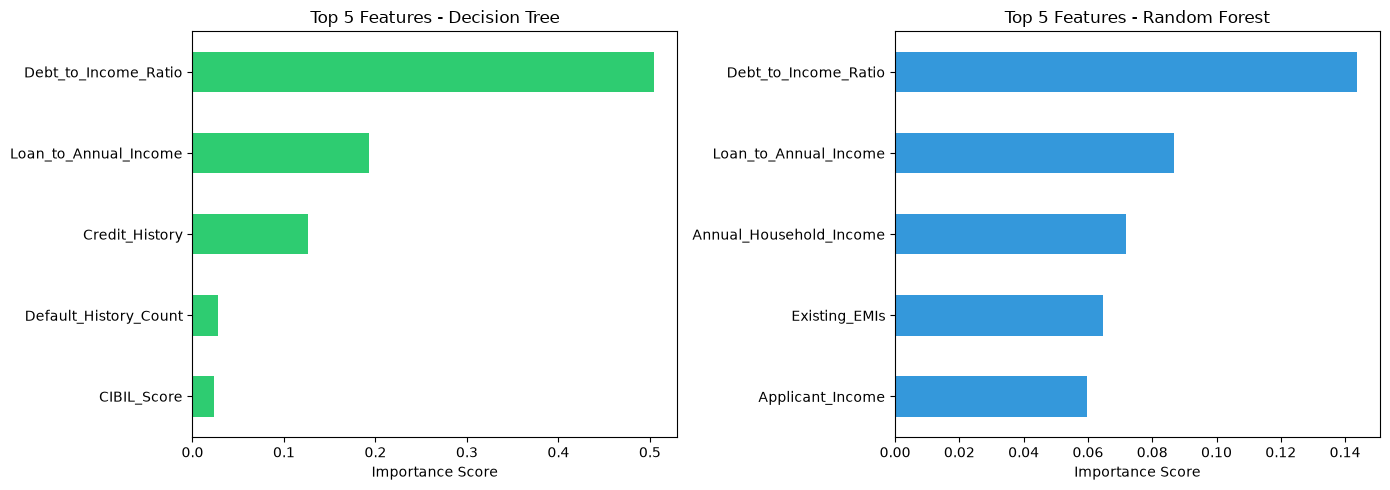

In [16]:
# Extract transformed feature names from ColumnTransformer
ohe = dt_pipeline.named_steps['preprocess'].named_transformers_['cat']
cat_encoded_names = ohe.get_feature_names_out(cat_features).tolist()
all_feature_names = cat_encoded_names + num_features

# Feature importances from Decision Tree
dt_importances = pd.Series(
    dt_pipeline.named_steps['model'].feature_importances_,
    index=all_feature_names
).sort_values(ascending=False)

# Feature importances from Random Forest
rf_importances = pd.Series(
    rf_pipeline.named_steps['model'].feature_importances_,
    index=all_feature_names
).sort_values(ascending=False)

print("=== Top 5 Features - Decision Tree ===")
print(dt_importances.head(5))

print("\n=== Top 5 Features - Random Forest ===")
print(rf_importances.head(5))

# Plot feature importances
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
dt_importances.head(5).plot(kind='barh', ax=axes[0], color='#2ecc71', title='Top 5 Features - Decision Tree')
axes[0].invert_yaxis()
axes[0].set_xlabel('Importance Score')

rf_importances.head(5).plot(kind='barh', ax=axes[1], color='#3498db', title='Top 5 Features - Random Forest')
axes[1].invert_yaxis()
axes[1].set_xlabel('Importance Score')

plt.tight_layout()
plt.show()

### 📝 Exercise 1 Findings & Business Insights
1. **Which features influence loan approval the most?**
   - **`Debt_to_Income_Ratio`** is the single most dominant feature across both models, followed closely by **`Loan_to_Annual_Income`**.
   - Additional influential features include **`Credit_History`**, **`Annual_Household_Income`**, and **`Existing_EMIs`**.

2. **Do both models agree on the top features?**
   - **Yes, on the core risk drivers:** Both models agree that `Debt_to_Income_Ratio` and `Loan_to_Annual_Income` are the top 2 features.
   - **Difference in distribution:**
     - **Decision Tree** concentrates over **50%** of its split importance solely on `Debt_to_Income_Ratio`.
     - **Random Forest** aggregates splits across hundreds of trees, distributing importance more evenly across financial capacity metrics (`Debt_to_Income_Ratio`, `Loan_to_Annual_Income`, `Annual_Household_Income`, `Existing_EMIs`, `Applicant_Income`).

## 🧠 Exercise 2
📌 **Model Tuning & Overfitting Check**

**Task:**
1. Train a Decision Tree with `max_depth=None` (unconstrained).
2. Train another Decision Tree with `max_depth=4` (constrained).
3. Compare:
   - Training accuracy
   - Test accuracy

**Questions to answer:**
- Which model overfits?
- Why does depth control matter in loan risk models?

In [17]:
# 1. Unconstrained Decision Tree (max_depth=None)
dt_unconstrained = Pipeline([
    ('preprocess', preprocessor),
    ('model', DecisionTreeClassifier(max_depth=None, random_state=42))
])
dt_unconstrained.fit(X_train, y_train)
train_acc_none = accuracy_score(y_train, dt_unconstrained.predict(X_train))
test_acc_none = accuracy_score(y_test, dt_unconstrained.predict(X_test))

# 2. Constrained Decision Tree (max_depth=4)
dt_constrained = Pipeline([
    ('preprocess', preprocessor),
    ('model', DecisionTreeClassifier(max_depth=4, random_state=42))
])
dt_constrained.fit(X_train, y_train)
train_acc_4 = accuracy_score(y_train, dt_constrained.predict(X_train))
test_acc_4 = accuracy_score(y_test, dt_constrained.predict(X_test))

# 3. Comparison table
depth_comparison = pd.DataFrame({
    'Model Configuration': ['Decision Tree (max_depth=None)', 'Decision Tree (max_depth=4)'],
    'Train Accuracy': [train_acc_none, train_acc_4],
    'Test Accuracy': [test_acc_none, test_acc_4],
    'Overfitting Gap (Train - Test)': [train_acc_none - test_acc_none, train_acc_4 - test_acc_4]
})
depth_comparison

,Model Configuration,Train Accuracy,Test Accuracy,Overfitting Gap (Train - Test)
0,Decision Tree (max_depth=None),1.00,0.805,0.195
1,Decision Tree (max_depth=4),0.91,0.820,0.090


### 📝 Exercise 2 Findings & Business Insights
1. **Which model overfits?**
   - **`Decision Tree (max_depth=None)` severely overfits.** It achieves **100% (1.00)** accuracy on the training data, but its test accuracy plummets to **80.5% (0.805)**, showing an overfitting gap of **19.5%**.
   - In contrast, **`Decision Tree (max_depth=4)`** achieves **91.0%** train accuracy and **82.0%** test accuracy (overfitting gap of only **9.0%**), demonstrating significantly better out-of-sample generalization.

2. **Why does depth control matter in loan risk models?**
   - **Prevents memorizing noise:** In credit scoring, unconstrained trees memorize random individual customer anomalies, leading to brittle policies.
   - **Regulatory compliance & explainability:** Loan decisions in banking must be explainable to regulators and applicants. A shallow tree (e.g. depth 4) generates clear, interpretable business rules.
   - **Robust decision boundaries:** Constrained depth focuses the model on fundamental solvency factors (DTI, income, credit history) rather than idiosyncratic noise.